# Sim 1: `command_a_plus_baseline_v2`

Historical 2025/26 Fantasy Premier League run. One Cohere model manages a single team, one Gameweek at a time. The model chooses the strategy. Rules, scoring, the information boundary, and state transitions are deterministic.

The recipe is `configs/baseline.yaml`. `Simulation.from_config()` loads it and wires the pieces below. The run title stored on the simulation row is **Command A+ Baseline**.

## What this recipe turns on

| Piece | Setting |
| --- | --- |
| Model | Cohere `command-a-plus-05-2026`, temperature `0.3`, seed `42` |
| Skill | `skills/baseline/SKILL.md` (`baseline_v2`), prepended to the system prompt every Gameweek |
| Tools | `core_v1` |
| Memory | `none`. There is no strategy notebook between Gameweeks. The previous Gameweek result is still included in the brief. |
| Reflection | off |
| Subagents | off. One model handles the whole Gameweek. |
| Limits | 60 tool calls and 60 turns per Gameweek. At the tool-call cap the agent is told to lock with `submit_lineup`. |
| World | `final_fpl/` CSVs, `dataset_version: v1` |
| Rules | `configs/rules/fpl_2025_26.yaml` |
| Season | `2025_26`, mode `historical` |
| Tracking | Databricks MLflow. Experiment is `MLFLOW_EXPERIMENT_ID`, or `/Shared/fpl_sim` when that is unset. |

`memory`, `reflection`, and `subagents` are logged with the run. They do not add a second pass or another model in this recipe.

## Layers

```text
CohereAgent  (command-a-plus-05-2026)
  system prompt = harness prefix + baseline skill
  user brief    = this Gameweek's manager state
        |
        v
core_v1 tools  (ToolContext.dispatch)
        |
        +--> FPLWorldRepository     reads, time-bounded
        +--> FPLRulesEngine         validates squad, lineup, transfers, chips
        |
        v
accepted submit_lineup locks the Gameweek
        |
        v
Manager store  (Supabase, or in-memory if Supabase is unavailable)
        |
        v
resolve_current  scores the locked XI (autosubs, captaincy, chips, hits)
```

1. **Agent.** `CohereAgent` runs a chat loop. Each model response is a turn. Each function call is a tool call. Tools stay attached for the whole session, and the model decides when to call them. Traces for the LLM turns and tool calls go to the Databricks experiment.

2. **Skill.** Process, separate from the rules. The playbook tells the model how to rank by position, which season of stats to trust, and when a chip is worth playing. At GW1, counting stats on the snapshot are last season, so the skill points the model at `search_players(..., season="2024_25")`. From GW2, `season="current"` is 2025/26 season-to-date. The rules engine still rejects anything illegal.

3. **Tools (`core_v1`).** Read tools return a shortlist, not a raw table dump:
   - `search_players`, `get_player`, `compare_players`, `get_player_performance`
   - `get_team_fixtures`, `get_standings`, `get_historical_results`
   - `get_manager_state`

   Write tools draft a decision until lock:
   - GW1: `submit_initial_squad`, then `submit_lineup`
   - GW2+: optional `submit_transfers` and `play_chip`, then `submit_lineup`

   An accepted `submit_lineup` locks the starting XI, bench order, captain, and vice-captain. A rejected call returns errors and saves nothing. If the agent never locks a valid lineup, the Gameweek is not written.

   `extended_v1` (`get_player_fixture_history`, `get_team_results`, `get_top_performers`) is not attached.

4. **World.** `HistoricalCSVWorld` reads the immutable `final_fpl/` bundle. `FPLWorldRepository` is the information boundary. While the agent is deciding, the phase is `pre_deadline`: the latest visible performances are the previous Gameweek (none at GW1), and the player and fixture snapshot is this deadline only. `future_leakage_protection` in the config is a label; the repository enforces the cutoff.

5. **Rules.** `FPLRulesEngine` loads `fpl_2025_26.yaml`. £100.0m budget, a 15-player squad (2/5/5/3, max 3 per club), a legal XI, free-transfer accrual (cap 5, GW1 starts at 0), −4 hits, and two halves of wildcard, free hit, bench boost, and triple captain. `score_gameweek` applies minutes, autosubs, captain and triple-captain multipliers, bench boost, and the transfer hit. The model cannot override any of this.

6. **Store.** One simulation row, one Gameweek row per lock, squad members, chip entitlements, and per-player points. `select_initial_team()` creates the simulation and locks GW1. `resolve_current()` switches the world to `post_gameweek`, scores the locked XI, and marks the Gameweek completed. `advance()` resolves the locked Gameweek and then locks the next one. `run_season()` walks all 38. A free hit restores the pre-chip squad and bank before the next brief. Free transfers accrue and selling prices refresh at that same boundary.

7. **Tracking.** The MLflow run name is `command_a_plus_baseline_v2`. The config, skill, and ruleset are logged as artifacts. Per-Gameweek metrics cover tool calls, invalid actions, tokens, latency, and points.

## One Gameweek

1. Set the world to `pre_deadline` for this Gameweek.
2. Build the system prompt and the brief: bank, free transfers, current squad, and from GW2 the previous score, FPL average, highest score, captain, bench points, and hit.
3. The agent investigates with read tools and drafts actions. Rejected actions come back as errors.
4. `submit_lineup` locks the XI.
5. `resolve_current` reads that Gameweek's performances and writes gross points, the hit, and the season total.
6. The next brief is built from the squad that actually carries forward.


Matplotlib is building the font cache; this may take a moment.


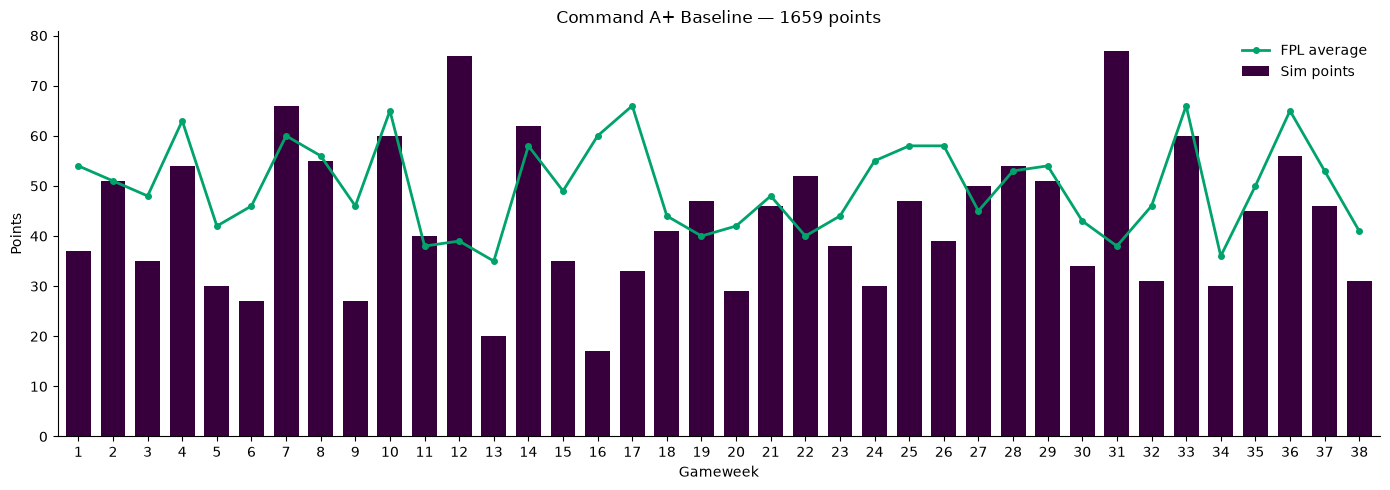

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / ".env")

from fpl_sim.storage.supabase import SupabaseStore

store = SupabaseStore()
sims = (
    store.client.table("simulations")
    .select("id,name,config_name,status,total_points,created_at")
    .eq("config_name", "command_a_plus_baseline_v2")
    .order("created_at")
    .execute()
    .data
    or []
)
completed = [row for row in sims if row.get("status") == "completed"]
if not completed:
    raise RuntimeError("No completed command_a_plus_baseline_v2 simulation in Supabase.")
sim = completed[0]

rows = (
    store.client.table("manager_gameweeks")
    .select("gw,net_points")
    .eq("simulation_id", sim["id"])
    .eq("status", "completed")
    .order("gw")
    .execute()
    .data
    or []
)
points = pd.DataFrame(rows)
if points.empty:
    raise RuntimeError(f"Simulation {sim['id']} has no completed gameweeks.")
points["gw"] = points["gw"].astype(int)
points["net_points"] = points["net_points"].astype(int)
points = points.sort_values("gw")

awards = pd.read_csv(ROOT / "final_fpl" / "gw_awards" / "gameweek_awards.csv")
chart = points.merge(
    awards[["gameweek", "average_manager_score"]],
    left_on="gw",
    right_on="gameweek",
    how="left",
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(
    chart["gw"],
    chart["net_points"],
    color="#37003c",
    width=0.72,
    label="Sim points",
    zorder=2,
)
ax.plot(
    chart["gw"],
    chart["average_manager_score"],
    color="#00a36a",
    marker="o",
    markersize=4,
    linewidth=2,
    label="FPL average",
    zorder=3,
)
ax.set_title(f"{sim['name']} — {int(sim['total_points'])} points")
ax.set_xlabel("Gameweek")
ax.set_ylabel("Points")
ax.set_xticks(chart["gw"])
ax.set_xlim(0.4, float(chart["gw"].max()) + 0.6)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


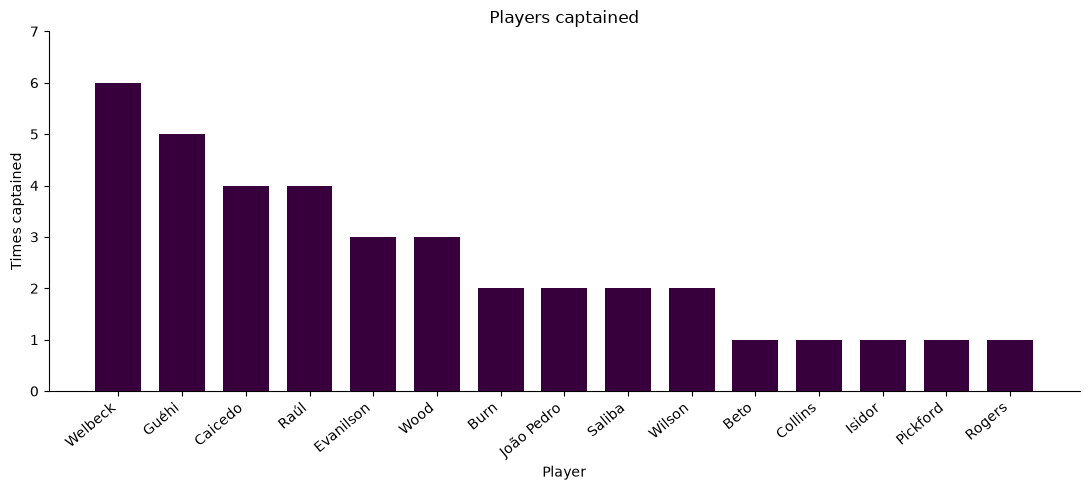

In [2]:
gw_rows = (
    store.client.table("manager_gameweeks")
    .select("id,gw")
    .eq("simulation_id", sim["id"])
    .eq("status", "completed")
    .order("gw")
    .execute()
    .data
)
gw_of = {row["id"]: int(row["gw"]) for row in gw_rows}
squad = (
    store.client.table("squad_players")
    .select("manager_gameweek_id,player_id,is_captain")
    .in_("manager_gameweek_id", list(gw_of))
    .eq("is_captain", True)
    .execute()
    .data
)
profiles = pd.read_csv(
    ROOT / "final_fpl" / "gw_player_profile" / "pre_gw38_player_stats.csv",
    usecols=["id", "web_name"],
)
name_of = dict(zip(profiles["id"].astype(int), profiles["web_name"]))

captains = pd.DataFrame(squad)
captains["gw"] = captains["manager_gameweek_id"].map(gw_of)
captains["player_id"] = captains["player_id"].astype(int)
captains["player"] = captains["player_id"].map(name_of)

times = (
    captains.groupby(["player_id", "player"], as_index=False)
    .size()
    .rename(columns={"size": "times"})
    .sort_values(["times", "player"], ascending=[False, True])
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(times["player"], times["times"], color="#37003c", width=0.72)
ax.set_title("Players captained")
ax.set_xlabel("Player")
ax.set_ylabel("Times captained")
ax.set_ylim(0, int(times["times"].max()) + 1)
ax.yaxis.set_major_locator(plt.MultipleLocator(1))
ax.tick_params(axis="x", rotation=40)
for label in ax.get_xticklabels():
    label.set_ha("right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


In [3]:
point_rows = (
    store.client.table("player_points")
    .select("manager_gameweek_id,player_id,raw_points,multiplier,counted_points")
    .in_("manager_gameweek_id", list(gw_of))
    .execute()
    .data
)
scored = pd.DataFrame(point_rows)
scored["player_id"] = scored["player_id"].astype(int)
armband = captains.merge(scored, on=["manager_gameweek_id", "player_id"], how="left")

captain_returns = (
    armband.groupby("player", as_index=False)
    .agg(
        times=("gw", "size"),
        gameweeks=("gw", lambda gws: ", ".join(str(gw) for gw in sorted(gws))),
        raw_points=("raw_points", "sum"),
        captain_points=("counted_points", "sum"),
        did_not_play=("multiplier", lambda values: int((values == 0).sum())),
    )
    .sort_values(["times", "captain_points"], ascending=[False, False])
    .reset_index(drop=True)
)
captain_returns


,player,times,gameweeks,raw_points,captain_points,did_not_play
0,Welbeck,6,"13, 14, 15, 20, 32, 33",16,32,0
1,Guéhi,5,"8, 17, 18, 29, 30",10,20,0
2,Caicedo,4,"9, 10, 11, 12",14,28,1
3,Raúl,4,"16, 25, 28, 36",9,18,1
4,Wood,3,"3, 5, 6",6,12,0
5,Evanilson,3,"1, 2, 34",3,6,1
6,Burn,2,"4, 7",17,34,0
7,Wilson,2,"19, 31",11,22,0
8,João Pedro,2,"35, 37",8,16,1
9,Saliba,2,"23, 27",3,6,0


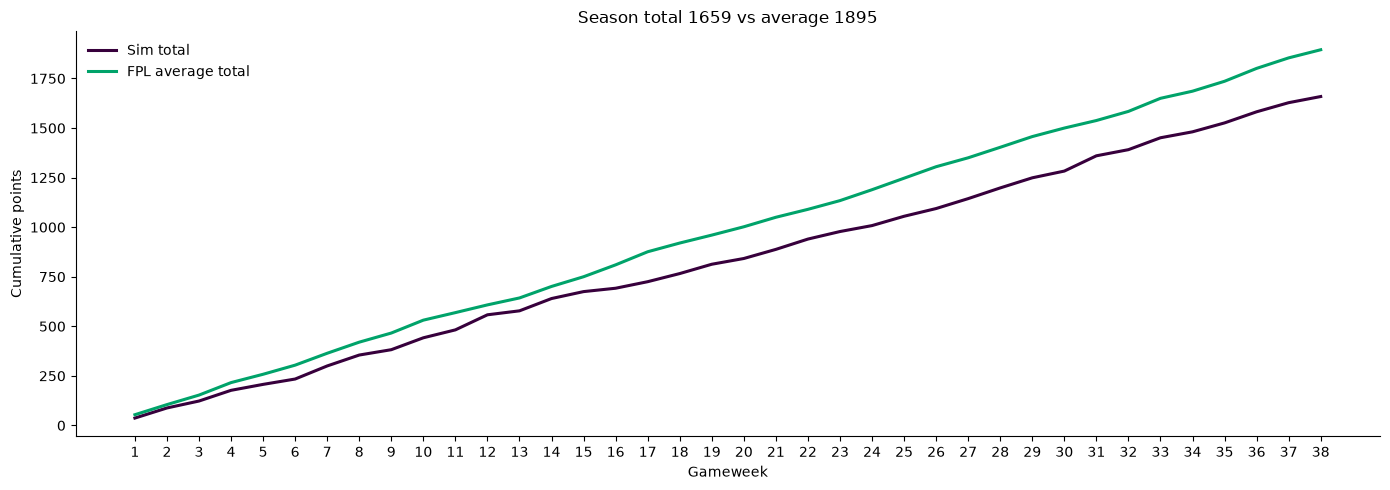

In [4]:
running = chart.sort_values("gw").copy()
running["sim_total"] = running["net_points"].cumsum()
running["average_total"] = running["average_manager_score"].cumsum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(running["gw"], running["sim_total"], color="#37003c", linewidth=2.2, label="Sim total")
ax.plot(
    running["gw"],
    running["average_total"],
    color="#00a36a",
    linewidth=2.2,
    label="FPL average total",
)
ax.set_title(
    f"Season total {int(running['sim_total'].iloc[-1])} vs "
    f"average {int(running['average_total'].iloc[-1])}"
)
ax.set_xlabel("Gameweek")
ax.set_ylabel("Cumulative points")
ax.set_xticks(running["gw"])
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


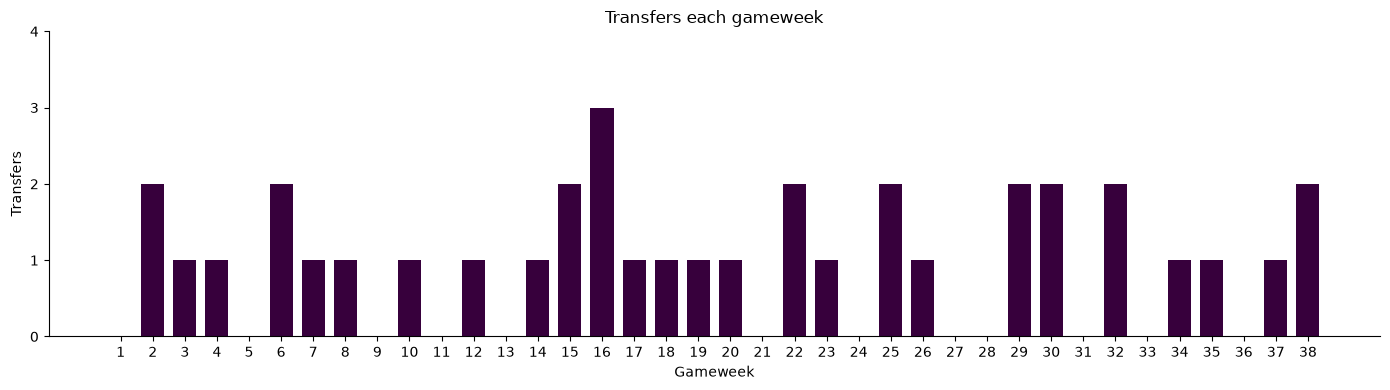

,Metric,Value
0,Season points,1659
1,FPL average total,1895
2,Points vs average,-236
3,Gameweeks above the average,9 of 38
4,Transfers,37
5,Transfer hits,-4
6,Chips played,None
7,Captain points,210
8,Weeks the captain did not play,4


In [5]:
transfer_rows = (
    store.client.table("transfers")
    .select("manager_gameweek_id")
    .in_("manager_gameweek_id", list(gw_of))
    .execute()
    .data
    or []
)
chips = (
    store.client.table("simulation_chips")
    .select("chip_type,entitlement,used_gw")
    .eq("simulation_id", sim["id"])
    .execute()
    .data
    or []
)
gw_detail = (
    store.client.table("manager_gameweeks")
    .select("gw,transfer_hit")
    .eq("simulation_id", sim["id"])
    .eq("status", "completed")
    .order("gw")
    .execute()
    .data
)
hits = pd.DataFrame(gw_detail)
hits["gw"] = hits["gw"].astype(int)
hits["transfer_hit"] = hits["transfer_hit"].fillna(0).astype(int)

moves = pd.Series(0, index=range(1, 39), name="transfers")
if transfer_rows:
    counted = pd.Series(transfer_rows).map(lambda row: gw_of[row["manager_gameweek_id"]]).value_counts()
    moves.update(counted)

chip_names = {"wildcard": "Wildcard", "freehit": "Free Hit", "bboost": "Bench Boost", "3xc": "Triple Captain"}
played = [
    f"{chip_names.get(row['chip_type'], row['chip_type'])} GW{int(row['used_gw'])}"
    for row in chips
    if row.get("used_gw") is not None
]
above = int((chart["net_points"] > chart["average_manager_score"]).sum())
gap = int(running["sim_total"].iloc[-1] - running["average_total"].iloc[-1])

summary = pd.DataFrame(
    [
        ["Season points", int(running["sim_total"].iloc[-1])],
        ["FPL average total", int(running["average_total"].iloc[-1])],
        ["Points vs average", gap],
        ["Gameweeks above the average", f"{above} of {len(chart)}"],
        ["Transfers", int(moves.sum())],
        ["Transfer hits", int(hits["transfer_hit"].sum())],
        ["Chips played", ", ".join(played) if played else "None"],
        ["Captain points", int(captain_returns["captain_points"].sum())],
        ["Weeks the captain did not play", int(captain_returns["did_not_play"].sum())],
    ],
    columns=["Metric", "Value"],
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(moves.index, moves.values, color="#37003c", width=0.72)
ax.set_title("Transfers each gameweek")
ax.set_xlabel("Gameweek")
ax.set_ylabel("Transfers")
ax.set_xticks(moves.index)
ax.set_ylim(0, max(int(moves.max()) + 1, 1))
ax.yaxis.set_major_locator(plt.MultipleLocator(1))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

summary
